# Experience reproductible CDC Diabetes Health Indicators
Comparaison mesuree sur le CSV officiel UCI 891, distinct des donnees inconnues des anciens artefacts. Voir les sorties executees et RESULTS.md.


In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd()
if ROOT.name != 'ml_api':
    ROOT = ROOT / 'ml_api'
ROOT = ROOT.resolve()
sys.path.insert(0, str(ROOT))
from training import run_experiment
CSV_PATH = Path(os.environ.get('ML_DATA_PATH', str(ROOT / 'data' / 'uci_891.csv')))
OUTPUT = Path(os.environ.get('ML_RUN_DIR', str(ROOT / 'runs' / 'uci_891_seed42')))
TARGET = os.environ.get('ML_TARGET', 'Diabetes_binary')
PROVENANCE = os.environ.get('ML_PROVENANCE_PATH')
if PROVENANCE is None and CSV_PATH.resolve() == (ROOT / 'data' / 'uci_891.csv').resolve():
    PROVENANCE = ROOT / 'data' / 'uci_891_provenance.json'
if not CSV_PATH.is_file():
    raise FileNotFoundError(f'Fournir un CSV reel : {CSV_PATH}. Voir fetch_data.py.')


## Protocole
Cible : 0 sans diabete, 1 prediabete ou diabete (UCI). Doublons exacts retires, vecteurs identiques groupes. Cinq plis externes : un pour le test, un pour la calibration, trois pour entrainement (environ 20/20/60 %). Validation croisee groupee a cinq plis sur entrainement. Selection par average precision de validation, avant test. Variante XGBoost avec SMOTENC dans chaque pli, jamais sur calibration/test. RandomForest : 100 arbres, profondeur 12 ; XGBoost : 200 arbres, profondeur 3. Parametres fixes avant execution. Seuil 0,5.


In [2]:
cv_summary, test_metrics, manifest = run_experiment(CSV_PATH, OUTPUT, TARGET, PROVENANCE)
display(cv_summary)
display(test_metrics)
print('Meilleur en validation :', manifest['selected_by_training_cv_average_precision'])
print('Variante XGBoost pour API :', manifest['api_model_name'])
print('SHA-256 artefact API :', manifest['api_artifact']['sha256'])


Training CV: dummy


Training CV: logistic_regression


Training CV: random_forest


Training CV: xgboost


Training CV: xgboost_smotenc


...

Fitting and evaluating: xgboost


Fitting and evaluating: xgboost_smotenc


roc_auc           average_precision            \
                         mean       std              mean       std   
model                                                                 
dummy                0.500000  0.000000          0.178585  0.001423   
logistic_regression  0.786549  0.001636          0.419033  0.005157   
random_forest        0.796601  0.001851          0.444376  0.003303   
xgboost              0.798539  0.001890          0.448246  0.004019   
xgboost_smotenc      0.791297  0.001234          0.435853  0.005173   

                    balanced_accuracy                  f1              recall  \
                                 mean       std      mean       std      mean   
model                                                                           
dummy                        0.500000  0.000000  0.000000  0.000000  0.000000   
logistic_regression          0.561198  0.002695  0.234718  0.007241  0.149651   
random_forest                0.553667  0.001086  0.207904  0.003635  0.125968   
xgboost                      0.567148  0.001741  0.249770  0.005153  0.158861   
xgboost_smotenc              0.707253  0.002714  0.475545  0.003978  0.650337   

                                  brier            
                          std      mean       std  
model                                              
dummy                0.000000  0.146693  0.000915  
logistic_regression  0.005180  0.123959  0.000841  
random_forest        0.002933  0.121475  0.000822  
xgboost              0.004655  0.120939  0.000780  
xgboost_smotenc      0.006148  0.162011  0.000366

roc_auc  average_precision  accuracy  \
model               calibration                                          
dummy               raw          0.500000           0.174566  0.825434   
                    sigmoid      0.500000           0.174566  0.825434   
logistic_regression raw          0.789943           0.409094  0.827954   
                    sigmoid      0.789943           0.409094  0.827927   
random_forest       raw          0.799938           0.437284  0.830712   
                    sigmoid      0.799938           0.437284  0.831296   
xgboost             raw          0.802639           0.443217  0.832648   
                    sigmoid      0.802639           0.443217  0.832250   
xgboost_smotenc     raw          0.795034           0.429265  0.745578   
                    sigmoid      0.795034           0.429265  0.830367   

                                 balanced_accuracy  precision    recall  \
model               calibration                                           
dummy               raw                   0.500000   0.000000  0.000000   
                    sigmoid               0.500000   0.000000  0.000000   
logistic_regression raw                   0.559868   0.525634  0.147979   
                    sigmoid               0.558594   0.525938  0.144789   
random_forest       raw                   0.551775   0.569923  0.123215   
                    sigmoid               0.567224   0.558005  0.161501   
xgboost             raw                   0.566545   0.575388  0.157703   
                    sigmoid               0.569838   0.566340  0.166667   
xgboost_smotenc     raw                   0.709914   0.370606  0.655120   
                    sigmoid               0.560492   0.553633  0.145852   

                                       f1     brier  log_loss  \
model               calibration                                 
dummy               raw          0.000000  0.144109  0.463108   
                    sigmoid      0.000000  0.144094  0.463057   
logistic_regression raw          0.230943  0.121905  0.383632   
                    sigmoid      0.227067  0.121898  0.383604   
random_forest       raw          0.202623  0.119344  0.375583   
                    sigmoid      0.250501  0.119276  0.374719   
xgboost             raw          0.247555  0.118631  0.373318   
                    sigmoid      0.257542  0.118637  0.373106   
xgboost_smotenc     raw          0.473404  0.160518  0.477280   
                    sigmoid      0.230880  0.120171  0.378014   

                                 ece_10_uniform_bins  
model               calibration                       
dummy               raw                     0.004020  
                    sigmoid                 0.001169  
logistic_regression raw                     0.011508  
                    sigmoid                 0.011995  
random_forest       raw                     0.010315  
                    sigmoid                 0.004198  
xgboost             raw                     0.007386  
                    sigmoid                 0.005922  
xgboost_smotenc     raw                     0.175710  
                    sigmoid                 0.004882

Meilleur en validation : xgboost
Variante XGBoost pour API : xgboost
SHA-256 artefact API : 5f55d74b4315933ae3fb72c00b969b0234875f9de519794d4c06985fcbfce3f1


## Evaluation et calibration
ROC-AUC, average precision, rappel, F1, precision, accuracy, balanced accuracy, Brier, log-loss et ECE a dix intervalles uniformes. Probabilites brutes et calibrees par sigmoide ajustee sur la seule partition de calibration. Export des effectifs, probabilites moyennes et frequences observees par intervalle. Les scores test ne servent pas au choix du modele.


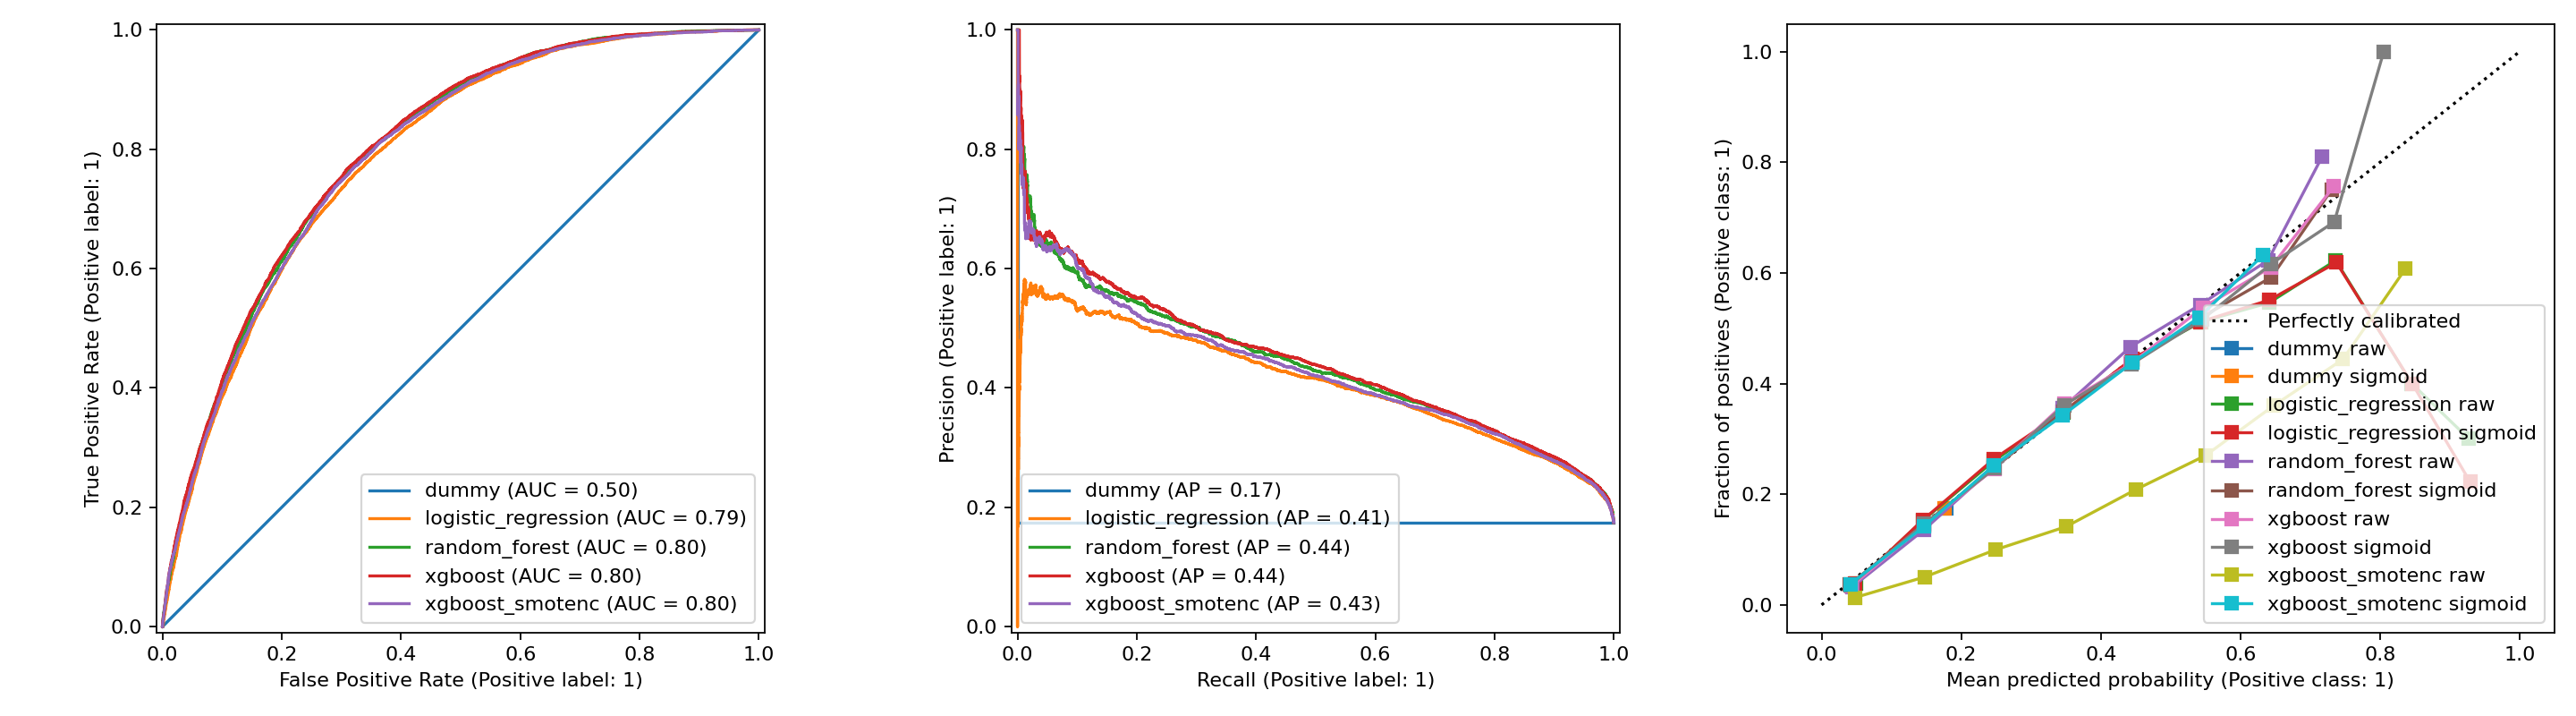

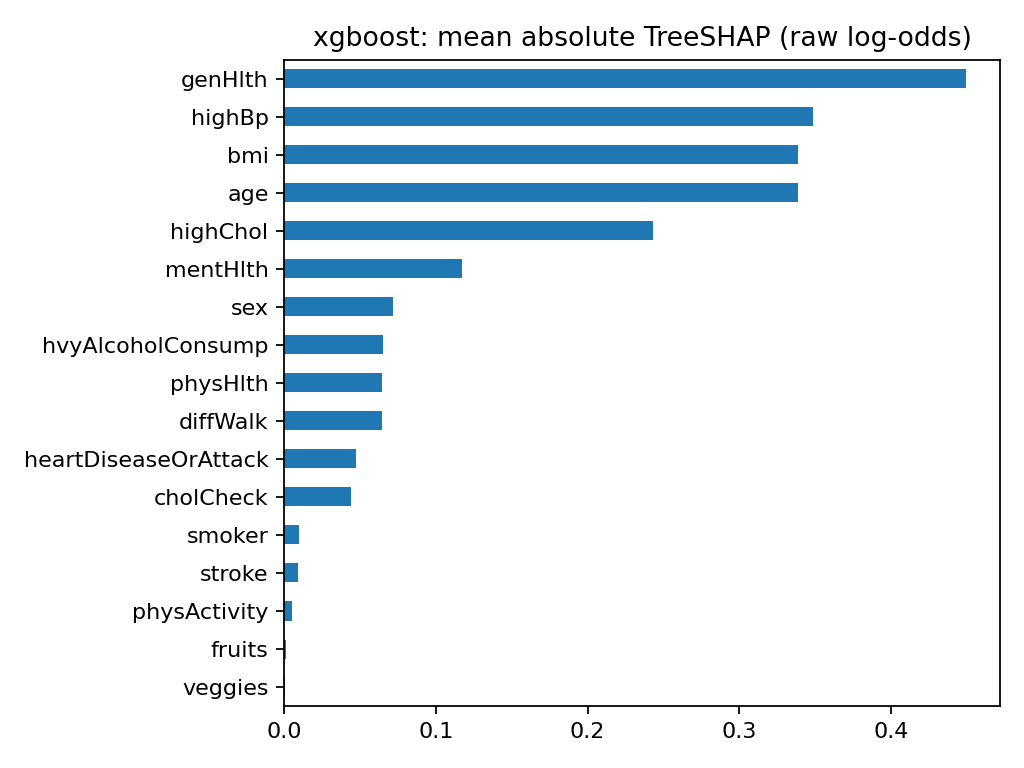

In [3]:
from IPython.display import Image, display
display(Image(filename=str(OUTPUT / 'evaluation.png')))
display(Image(filename=str(OUTPUT / 'shap_importance.png')))


## SHAP et lien avec API
TreeSHAP exact sur au plus 500 observations test de la variante XGBoost choisie en validation. Base + contributions = log-odds brut ; sa sigmoide donne rawModelProbability. riskScore est la probabilite apres calibration sigmoide. Le bundle contient ce meme modele, scaler et calibrateur ; toutes ses probabilites test sont verifiees apres rechargement. Le SHA-256 lie artefact, evaluation et API.

## Reproductibilite et limites
Manifeste : provenance, empreintes du CSV et du bundle, partitions, plis, hyperparametres, versions, metriques. Les anciens fichiers sont conserves ; aucune evaluation independante de ces fichiers n?est revendiquee. La cible est un etat autod?clare existant, pas une incidence future ni un diagnostic. UCI est un jeu public documente, sans preuve qu?il correspond aux donnees des anciens modeles. La selection globale et la selection dans la famille XGBoost sont distinguees. Le test ne constitue pas une validation clinique ou externe au Maroc. Voir README.md.
